<div class="alert alert-primary" role="alert">

<h1 align="center">Seventh Practice: Interactive Paint Application</h1>

<h3>1. Canvas and Mouse Drawing</h3>
<p>Use a mouse callback to draw on the canvas. Convert window coordinates to canvas coordinates by subtracting the panel height from <code>y</code>.</p>

<h3>2. Color and Brush Controls</h3>
<p>Use OpenCV trackbars to adjust the R, G, B values and brush size. Display the selected color in a preview square.</p>

<h3>3. Undo, Redo, and Clear</h3>
<p>Save canvas copies in <code>undo_stack</code> and <code>redo_stack</code>. Use <code>z</code> to undo, <code>y</code> to redo, and <code>r</code> to clear the canvas.</p>

<h3>4. Window and Final Output</h3>
<p>Rebuild the window if it closes unexpectedly. Exit with <code>Esc</code> and display the finished drawing in Jupyter Notebook.</p>

</div>


<div class="alert alert-warning" role="alert" align="center">
    <h4>Marzieh Naseri</h4>
</div>

In [14]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt

In [15]:
WINDOW="image"
WIDTH=900
PANEL_HEIGHT=100
CANVA_HEIGHT=500
SQUARE_X=20
SQUARE_Y=25
SQUARE_SIZE=50

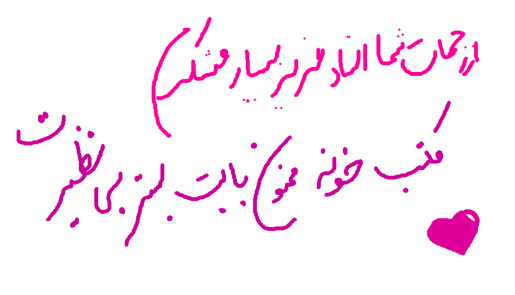

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


WINDOW = "Paint"
WIDTH, PANEL_HEIGHT, CANVAS_HEIGHT = 900, 100, 500
SQUARE_X, SQUARE_Y, SQUARE_SIZE = 20, 25, 50


canvas = np.full((CANVAS_HEIGHT, WIDTH, 3), 255, dtype=np.uint8)
undo_stack, redo_stack = [], []
drawing, last_point = False, None
brush_color, brush_size = (0, 0, 0), 5

def nothing(x): pass

def rebuild_window():
    cv2.namedWindow(WINDOW, cv2.WINDOW_AUTOSIZE)
    cv2.createTrackbar("R", WINDOW, 0, 255, nothing)
    cv2.createTrackbar("G", WINDOW, 0, 255, nothing)
    cv2.createTrackbar("B", WINDOW, 0, 255, nothing)
    cv2.createTrackbar("Size", WINDOW, 5, 100, nothing)
    cv2.setMouseCallback(WINDOW, draw)

def draw(event, x, y, flags, param):
    global drawing, last_point, brush_color, brush_size
    inside_canvas = (0 <= x < WIDTH and PANEL_HEIGHT <= y < PANEL_HEIGHT + CANVAS_HEIGHT)

    if event == cv2.EVENT_LBUTTONDOWN and inside_canvas:
        undo_stack.append(canvas.copy())
        redo_stack.clear()
       
        #slider's names
        r = cv2.getTrackbarPos("R", WINDOW)
        g = cv2.getTrackbarPos("G", WINDOW)
        b = cv2.getTrackbarPos("B", WINDOW)
        brush_size = max(1, cv2.getTrackbarPos("Size", WINDOW))
        brush_color = (b, g, r)
        drawing = True
        last_point = (x, y - PANEL_HEIGHT)
        cv2.circle(canvas, last_point, max(1, brush_size // 2), brush_color, -1)

    elif event == cv2.EVENT_MOUSEMOVE and drawing:
        if inside_canvas:
            current_point = (x, y - PANEL_HEIGHT)
            if last_point is None:
                cv2.circle(canvas, current_point, max(1, brush_size // 2), brush_color, -1)
            else:
                cv2.line(canvas, last_point, current_point, brush_color, brush_size)
            last_point = current_point
        else:
            last_point = None

    elif event == cv2.EVENT_LBUTTONUP:
        drawing = False
        last_point = None

#start
cv2.destroyAllWindows()
rebuild_window()

while True:
    try:
        
        r = cv2.getTrackbarPos("R", WINDOW)
        g = cv2.getTrackbarPos("G", WINDOW)
        b = cv2.getTrackbarPos("B", WINDOW)
        size = cv2.getTrackbarPos("Size", WINDOW)
    except cv2.error:
        rebuild_window()
        continue

    image = np.full((PANEL_HEIGHT + CANVAS_HEIGHT, WIDTH, 3), 255, dtype=np.uint8)
    cv2.rectangle(image, (SQUARE_X, SQUARE_Y), (SQUARE_X + SQUARE_SIZE, SQUARE_Y + SQUARE_SIZE), (b, g, r), -1)
    cv2.rectangle(image, (SQUARE_X, SQUARE_Y), (SQUARE_X + SQUARE_SIZE, SQUARE_Y + SQUARE_SIZE), (0, 0, 0), 2)
    
    cv2.putText(image, "Preview", (SQUARE_X + SQUARE_SIZE + 15, 42), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1)
    cv2.putText(image, "Z: Undo   Y: Redo   R: Clear   Esc: Exit", (SQUARE_X + SQUARE_SIZE + 15, 70), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1)
    cv2.line(image, (0, PANEL_HEIGHT - 1), (WIDTH - 1, PANEL_HEIGHT - 1), (0, 0, 0), 2)
    
    image[PANEL_HEIGHT:] = canvas
    cv2.imshow(WINDOW, image)

    key = cv2.waitKey(1) & 0xFF
    if key == 27: break
    elif key == ord("z") and undo_stack:
        redo_stack.append(canvas.copy()); canvas[:] = undo_stack.pop()
    elif key == ord("y") and redo_stack:
        undo_stack.append(canvas.copy()); canvas[:] = redo_stack.pop()
    elif key == ord("r"):
        undo_stack.append(canvas.copy()); redo_stack.clear(); canvas[:] = 255

cv2.destroyAllWindows()
plt.imshow(canvas[..., ::-1])
plt.axis('off')
plt.show()
